In [8]:
# ==================================
# IMPORTS
# ==================================

from pathlib import Path
import sys

import torch
import matplotlib.pyplot as plt

from dataset_gen import solve_poiseuille



In [13]:
nu = 0.01
G = 1.0
y = torch.linspace(0, 1, 501)
snapshots = solve_poiseuille(nu = 0.01,
                             G = 1.0,
                             Ny= 501,
                             T_final= 12.0)
u_final = snapshots[-1]

In [14]:
u_exact = (
    G / (2 * nu)
) * y * (1 - y)

In [15]:
print(y.shape)
print(u_final.shape)
print(u_exact.shape)

torch.Size([501])
torch.Size([501])
torch.Size([501])


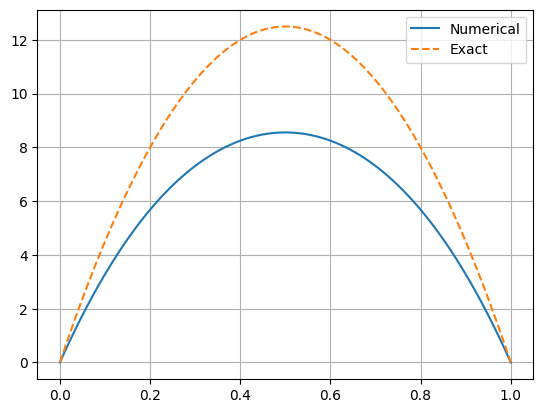

In [16]:
plt.plot(y, u_final, label="Numerical")
plt.plot(y, u_exact, "--", label="Exact")

plt.legend()
plt.grid(True)

In [18]:
import os
print(os.getcwd())

/Users/gopal/Python/Hello/FNO/Navier/poiseuille_flow


In [19]:
from dataset import PoiseuilleDataset
dataset = PoiseuilleDataset(
    "data/poiseuille_dataset_20.pt"
)

sample = dataset[0]

print(sample["a"].shape)
print(sample["u"].shape)

print(sample["a"][0].min(), sample["a"][0].max())  # u
print(sample["a"][2].mean())                       # ν channel
print(sample["a"][3].mean())                       # G channel

torch.Size([4, 501])
torch.Size([1, 501])
tensor(-1.0848) tensor(-1.0848)
tensor(-1.4818)
tensor(-1.0690)
